# Distancias fragmento–principal (GT)

Cuaderno consumidor: lee la tabla generada por `scripts/run_distancias_gt.py`
(`results/distancias/distancias_gt_3d.csv`, dataset completo) y presenta resúmenes e histogramas.
No ejecuta el cálculo.

In [1]:
from pathlib import Path
import pandas as pd

CSV = Path("../results/distancias/distancias_gt_3d.csv")
df = pd.read_csv(CSV, dtype={"case_id": str})
con = df[~df.principal]
print(f"{df.case_id.nunique()} casos · {len(con)} fragmentos conminutos · {df.region.nunique()} regiones")
df.head(12)

100 casos · 275 fragmentos conminutos · 3 regiones


,region,fragmento,principal,n_voxels,distancia_mm,case_id,split,fracture_type,modo
0,sacrum,1,True,458539,0.00000,001,train,UHF,3d
1,left_hipbone,11,True,762194,0.00000,001,train,UHF,3d
2,left_hipbone,12,False,63957,0.78125,001,train,UHF,3d
3,right_hipbone,21,True,844349,0.00000,001,train,UHF,3d
4,sacrum,1,True,323928,0.00000,002,train,SHF,3d
5,sacrum,2,False,39087,0.80000,002,train,SHF,3d
6,left_hipbone,11,True,502549,0.00000,002,train,SHF,3d
7,right_hipbone,21,True,470491,0.00000,002,train,SHF,3d
8,right_hipbone,22,False,15260,0.80000,002,train,SHF,3d
9,right_hipbone,23,False,19132,0.80000,002,train,SHF,3d


In [2]:
# Resumen por región (mm)
con.groupby("region")["distancia_mm"].describe()[["count", "min", "25%", "50%", "75%", "max"]].round(1)

,count,min,25%,50%,75%,max
region,,,,,,
left_hipbone,115.0,0.7,0.8,0.8,0.8,50.8
right_hipbone,107.0,0.6,0.8,0.8,0.8,73.1
sacrum,53.0,0.7,0.8,0.8,0.8,11.5


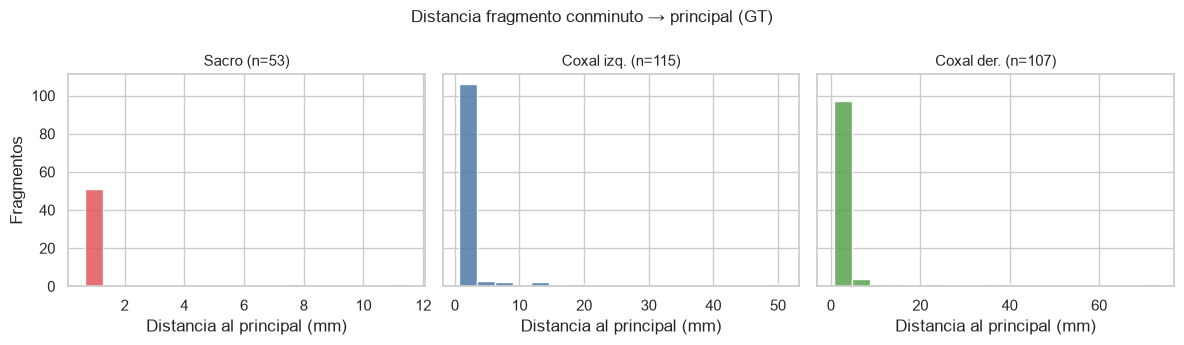

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
COLORES = {"sacrum": "#e15759", "left_hipbone": "#4e79a7", "right_hipbone": "#59a14f"}
NOMBRES = {"sacrum": "Sacro", "left_hipbone": "Coxal izq.", "right_hipbone": "Coxal der."}

fig, ejes = plt.subplots(1, 3, figsize=(12, 3.5), sharey=True)
for eje, (region, color) in zip(ejes, COLORES.items()):
    d = con.loc[con.region == region, "distancia_mm"]
    sns.histplot(d, bins=18, color=color, alpha=0.85, ax=eje)
    eje.set_title(f"{NOMBRES[region]} (n={len(d)})", fontsize=11)
    eje.set_xlabel("Distancia al principal (mm)")
    eje.set_ylabel("Fragmentos")
fig.suptitle("Distancia fragmento conminuto → principal (GT)", fontsize=12)
fig.tight_layout()
fig.savefig("../results/distancias/histogramas_gt.png", dpi=300, bbox_inches="tight")
plt.show()

In [4]:
# Los 10 fragmentos más alejados de su hueso
con.nlargest(10, "distancia_mm")[["case_id", "fracture_type", "region", "fragmento", "distancia_mm"]].reset_index(drop=True)

,case_id,fracture_type,region,fragmento,distancia_mm
0,096,BHF,right_hipbone,23,73.118287
1,085,SHF,left_hipbone,12,50.820687
2,054,BHF,right_hipbone,24,40.368669
3,039,SHF,right_hipbone,23,35.123064
4,005,BHF,right_hipbone,23,24.291985
5,024,SHF,left_hipbone,13,20.066722
6,099,SHF,left_hipbone,12,14.226777
7,054,BHF,right_hipbone,23,13.595506
8,084,SHF,left_hipbone,14,12.930488
9,037,SHF,sacrum,2,11.515205


## Distancia sobre las máscaras: real frente a predicha

Cada fila es un fragmento de un CT de test. El corte axial es el del punto del fragmento más cercano a su hueso.
- **Izquierda (real):** principal del hueso en azul, fragmento en naranja. La línea une los dos puntos más cercanos
  (EDT 3D con el espaciado del header). Si el punto del principal está en otro corte, se marca con × y se indica a
  cuántos cortes está.
- **Derecha (predicha por el modelo):** componente principal en azul y, si el modelo lo separó, el fragmento en
  naranja; en gris, el resto del hueso predicho (componentes más pequeños). El contorno blanco punteado es
  dónde está el fragmento real.

Los ejemplos se generan con `scripts/ejemplos_distancias.py` (mismo cálculo que `model3d evaluate`).

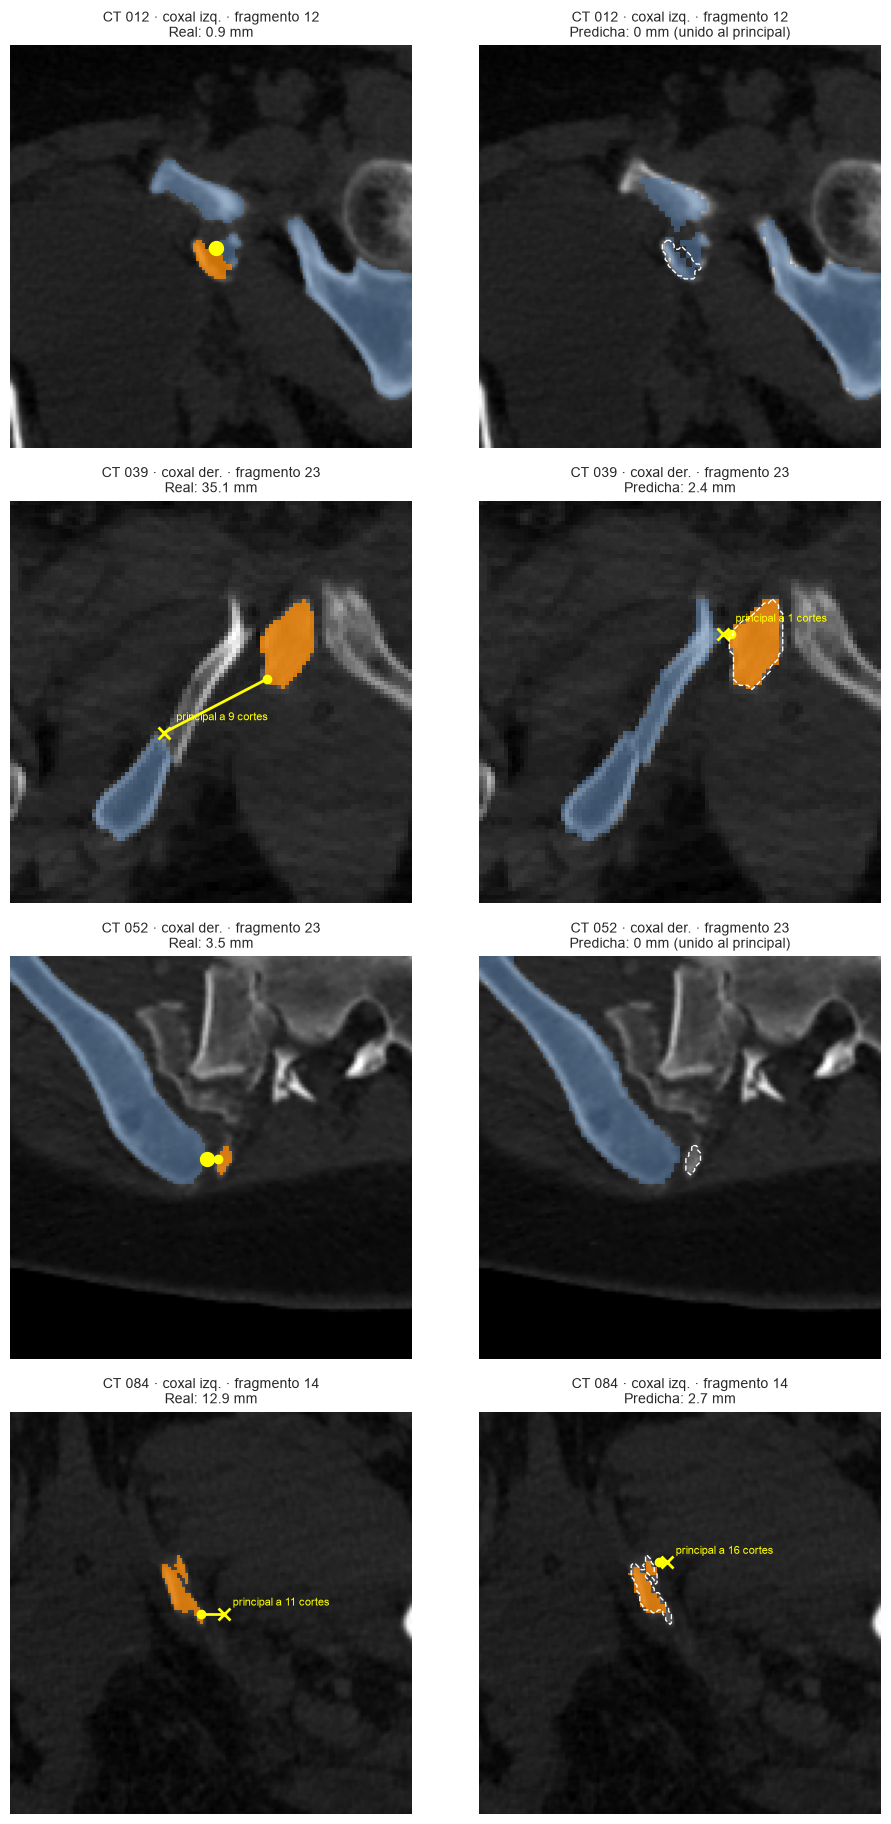

In [5]:
import numpy as np
from matplotlib.colors import ListedColormap

EJ = sorted(Path("../results/distancias/ejemplos").glob("*.npz"))
CMAP = ListedColormap([(0, 0, 0, 0), (0.31, 0.47, 0.65, 0.55), (0.96, 0.52, 0.0, 0.8), (0.6, 0.6, 0.6, 0.35)])
NOMBRE = {"sacrum": "sacro", "left_hipbone": "coxal izq.", "right_hipbone": "coxal der."}

def dibuja(ax, e, lab, p, q, d, titulo):
    ax.imshow(np.clip(e["ct"], -200, 1300), cmap="gray")
    ax.imshow(lab, cmap=CMAP, vmin=0, vmax=3, interpolation="nearest")
    if not np.isnan(p).any():
        ax.plot([p[2], q[2]], [p[1], q[1]], "-", color="yellow", lw=2)
        ax.plot(p[2], p[1], "o", color="yellow", ms=6)
        ax.plot(q[2], q[1], "x" if q[0] != 0 else "o", color="yellow", ms=9, mew=2)
        if q[0] != 0:
            ax.text(q[2] + 3, q[1] - 3, f"principal a {abs(int(q[0]))} cortes", color="yellow", fontsize=8)
    ax.set_title(titulo, fontsize=10)
    ax.axis("off")

fig, axes = plt.subplots(len(EJ), 2, figsize=(10, 4.6 * len(EJ)))
for (a1, a2), f in zip(axes, EJ):
    e = np.load(f, allow_pickle=True)
    caso = f"CT {e['case_id']} · {NOMBRE[str(e['region'])]} · fragmento {int(e['frag'])}"
    dibuja(a1, e, e["gt"], e["p_gt"], e["q_gt"], float(e["d_gt"]), f"{caso}\nReal: {float(e['d_gt']):.1f} mm")
    est = str(e["estado"])
    txt = {"separado": f"Predicha: {float(e['d_pred']):.1f} mm", "unido al principal": "Predicha: 0 mm (unido al principal)",
           "no detectado": "Predicha: fragmento no detectado"}[est]
    dibuja(a2, e, e["pred"], e["p_pr"], e["q_pr"], float(e["d_pred"]), f"{caso}\n{txt}")
    a2.contour(e["frag_gt"], levels=[0.5], colors="white", linewidths=1, linestyles="--")
plt.tight_layout()
plt.show()

**Qué se ve** (modelo `unet3d_cbam_trab`, cabeza semántica):
- **CT 012:** el fragmento toca su hueso (0,9 mm, un paso de rejilla) y el modelo lo deja unido (0 mm). Es lo correcto.
- **CT 039:** fragmento a 35 mm. El modelo lo segmenta completo y como componente aparte, pero la distancia predicha es
  de 2,4 mm: se mide al componente principal predicho, que no coincide con el real porque la red no separa los
  fragmentos que se tocan.
- **CT 052:** fragmento pequeño (0,26 cm³) a 3,5 mm. El modelo casi no lo segmenta (1 % de sus vóxeles): con vóxeles de
  1,56 mm casi desaparece.
- **CT 084:** fragmento pequeño a 12,9 mm. El modelo lo segmenta aparte, pero lo pone a 2,7 mm de un trozo del
  principal.
- **Limitación:** la distancia predicha depende de que la red separe bien el principal de los demás fragmentos. Con una
  máscara por hueso, eso solo pasa cuando hay un espacio visible.

### Real frente a predicha en todos los fragmentos de test

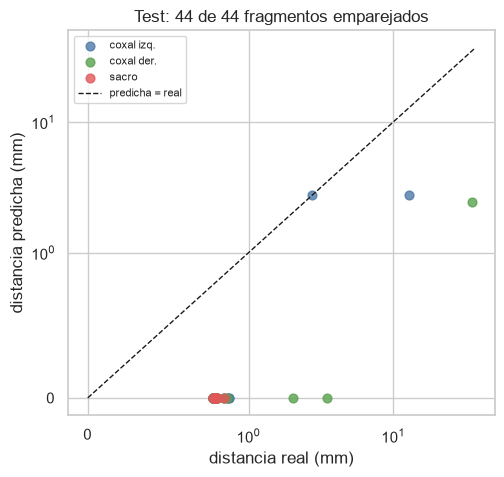

Error absoluto medio: 1.81 mm | no detectados: 0


In [6]:
dt = pd.read_csv("../results/detection/unet3d_cbam_trab/eval/distances_test.csv", dtype={"case_id": str})
ok = dt.dropna(subset=["dist_pred_mm"])
fig, ax = plt.subplots(figsize=(5.5, 5))
for reg, g in ok.groupby("region"):
    ax.scatter(g.dist_gt_mm, g.dist_pred_mm, s=40, alpha=0.8, color=COLORES[reg], label=NOMBRE[reg])
lim = max(dt.dist_gt_mm.max(), 1) * 1.05
ax.plot([0, lim], [0, lim], "k--", lw=1, label="predicha = real")
ax.set_xscale("symlog", linthresh=1); ax.set_yscale("symlog", linthresh=1)
ax.set_xlabel("distancia real (mm)"); ax.set_ylabel("distancia predicha (mm)")
ax.set_title(f"Test: {len(ok)} de {len(dt)} fragmentos emparejados")
ax.legend(fontsize=8)
plt.show()
print(f"Error absoluto medio: {(ok.dist_pred_mm - ok.dist_gt_mm).abs().mean():.2f} mm | no detectados: {dt.dist_pred_mm.isna().sum()}")